In [ ]:
# Import Required Libraries
import json
import re
from pathlib import Path

import pandas as pd
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Upload JSONs
ROOT = Path(".")

# Pattern to pick up the 4 files
json_files = sorted(ROOT.glob("RQ1_InternVL3-8B_continent_prompt*_r1.json"))
print("Found JSON files:", [p.name for p in json_files])

# Where to store backups of the original files
BACKUP = ROOT / "backup_originals"
BACKUP.mkdir(exist_ok=True)

In [ ]:
# Fields to drop
DROP_KEYS = {
    "dataset_split_hint",
    "temperature",
    "max_new_tokens",
    "do_sample",
    "model_repo",
    "image_size",
    "device",
    "dtype",
}

In [ ]:
# Utility Functions for Cleaning the JSONs
def infer_continent_country_from_path(image_path: str):
    """
    Paths look like:
      .../RQ1_Experiments/RQ1_Data_Batch1/<Continent>/<Country>/<file>

    We only READ image_path, never modify it.
    """
    parts = [p for p in image_path.split("/") if p]

    continent = None
    country = None

    # Find 'RQ1_Data_Batch1' anchor
    idx = None
    for i, p in enumerate(parts):
        if p == "RQ1_Data_Batch1":
            idx = i
            break

    if idx is not None and idx + 2 < len(parts):
        continent = parts[idx + 1]
        country = parts[idx + 2]
    else:
        # Fallback: assume <continent>/<country>/<file> at the end
        if len(parts) >= 3:
            continent = parts[-3]
            country = parts[-2]

    return continent, country

def clean_record(rec: dict):
    # 1) Fix model name
    if rec.get("model") == "InternVL3-8B":
        rec["model"] = "InternVL3"

    # 2) Drop unwanted keys
    for k in DROP_KEYS:
        rec.pop(k, None)

    # 3) Ensure dataset_continent / dataset_country from image_path
    img = rec.get("image_path")
    if isinstance(img, str):
        cont, country = infer_continent_country_from_path(img)
        if cont is not None:
            rec["dataset_continent"] = cont
        if country is not None:
            rec["dataset_country"] = country

    return rec


Found JSON files: ['RQ1_InternVL3-8B_continent_prompt1_r1.json', 'RQ1_InternVL3-8B_continent_prompt2_r1.json', 'RQ1_InternVL3-8B_continent_prompt3_r1.json', 'RQ1_InternVL3-8B_continent_prompt4_r1.json']
Cleaning done.


In [ ]:
for path in json_files:
    # Read
    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    # Backup original
    backup_path = BACKUP / path.name
    with backup_path.open("w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

    # Clean (list of records or single dict)
    if isinstance(data, list):
        cleaned = [clean_record(rec) for rec in data]
    elif isinstance(data, dict):
        cleaned = clean_record(data)
    else:
        print(f"[WARN] Unexpected JSON structure in {path}, leaving as is.")
        cleaned = data

    # Write cleaned back to the same filename
    with path.open("w", encoding="utf-8") as f:
        json.dump(cleaned, f, ensure_ascii=False, indent=2)

print("Cleaning done.")

In [ ]:
# Canonicalisation (continents & labels)

continent_map = {
    "africa": "Africa",
    "asia": "Asia",
    "europe": "Europe",
    "north america": "North America",
    "south america": "South America",
    "central america": "North America",
    "latin america": "South America",
    "americas": "Americas",
    "caribbean": "Caribbean",
    "oceania": "Oceania",
    "australia": "Oceania",
    "middle east": "Asia",
    "mesoamerica": "South America",
    "indigenous americas": "Americas",
}

continent_pattern = re.compile(
    r"(north america|south america|central america|latin america|africa|asia|europe|"
    r"caribbean|americas|oceania|australia|middle east|mesoamerica|indigenous americas)",
    re.IGNORECASE,
)


def canonicalise_continent(text: str):
    if not isinstance(text, str):
        return None
    m = continent_pattern.search(text.lower())
    if not m:
        return None
    key = m.group(1).lower()
    return continent_map.get(key)


label_map = {
    "political expression": "political expression",
    "vandalism": "vandalism",
    "decoration": "decoration",
    "cultural identity": "cultural identity",
    "advertisement": "advertisement",
}

label_pattern = re.compile(
    r"(political expression|vandalism|decoration|cultural identity|advertisement)",
    re.IGNORECASE,
)


def canonicalise_label(text: str):
    if not isinstance(text, str):
        return None
    m = label_pattern.search(text.lower())
    if not m:
        return None
    key = m.group(1).lower()
    return label_map.get(key)

In [ ]:
# Prompt-specific Parsers

def parse_prompt1(row):
    """
    Prompt 1 output shape:
        1) <continent-ish sentence>
        2) <label-ish sentence>
    """
    out = row.get("output", "") or ""
    pred_continent_raw = None
    pred_label_raw = None

    # Continent (look around "1)")
    m1 = re.search(r"1\)\s*(.+?)(?:\n\s*2\)|$)", out, flags=re.DOTALL)
    if m1:
        cont_text = m1.group(1)
        m_cont = continent_pattern.search(cont_text)
        if m_cont:
            pred_continent_raw = m_cont.group(0)

    # Label (look around "2)")
    m2 = re.search(r"2\)\s*(.+)$", out, flags=re.DOTALL)
    if m2:
        label_text = m2.group(1)
        m_lab = label_pattern.search(label_text)
        if m_lab:
            pred_label_raw = m_lab.group(0)

    return pd.Series(
        {
            "pred_continent_raw": pred_continent_raw,
            "pred_continent": canonicalise_continent(pred_continent_raw),
            "pred_continent2_raw": None,
            "pred_continent2": None,
            "pred_continent2_pct": None,
            "pred_label_raw": pred_label_raw,
            "pred_label": canonicalise_label(pred_label_raw),
            "confidence": None,
        }
    )


def parse_prompt2(row):
    """
    Prompt 2 output shape:
      CONTINENT: ...
      LABEL: ...
      CONFIDENCE: 90%
    """
    out = row.get("output", "") or ""
    pred_continent_raw = None
    pred_label_raw = None
    confidence = None

    m_cont = re.search(r"CONTINENT:\s*([^\n]+)", out, flags=re.IGNORECASE)
    if m_cont:
        pred_continent_raw = m_cont.group(1).strip()

    m_lab = re.search(r"LABEL:\s*([^\n]+)", out, flags=re.IGNORECASE)
    if m_lab:
        pred_label_raw = m_lab.group(1).strip()

    m_conf = re.search(r"CONFIDENCE:\s*([0-9]+)", out, flags=re.IGNORECASE)
    if m_conf:
        try:
            confidence = int(m_conf.group(1))
        except ValueError:
            confidence = None

    return pd.Series(
        {
            "pred_continent_raw": pred_continent_raw,
            "pred_continent": canonicalise_continent(pred_continent_raw),
            "pred_continent2_raw": None,
            "pred_continent2": None,
            "pred_continent2_pct": None,
            "pred_label_raw": pred_label_raw,
            "pred_label": canonicalise_label(pred_label_raw),
            "confidence": confidence,
        }
    )


def parse_prompt3(row):
    """
    Prompt 3: multiple CONTINENT and LABEL lines (debate + moderator).
    Use last occurrence as moderator decision, with fallback to first.
    """
    out = row.get("output", "") or ""

    # Continents
    cont_matches = list(re.finditer(r"CONTINENT:\s*([A-Za-z ]+)", out, flags=re.IGNORECASE))
    pred_continent_raw = None
    pred_continent = None
    if cont_matches:
        pred_continent_raw = cont_matches[-1].group(1).strip()
        canon = canonicalise_continent(pred_continent_raw)
        if canon is None:
            pred_continent_raw = cont_matches[0].group(1).strip()
            canon = canonicalise_continent(pred_continent_raw)
        pred_continent = canon

    # Labels
    lab_matches = list(re.finditer(r"LABEL:\s*([A-Za-z ]+)", out, flags=re.IGNORECASE))
    pred_label_raw = None
    pred_label = None
    if lab_matches:
        pred_label_raw = lab_matches[-1].group(1).strip()
        canon_lab = canonicalise_label(pred_label_raw)
        if canon_lab is None:
            pred_label_raw = lab_matches[0].group(1).strip()
            canon_lab = canonicalise_label(pred_label_raw)
        pred_label = canon_lab

    return pd.Series(
        {
            "pred_continent_raw": pred_continent_raw,
            "pred_continent": pred_continent,
            "pred_continent2_raw": None,
            "pred_continent2": None,
            "pred_continent2_pct": None,
            "pred_label_raw": pred_label_raw,
            "pred_label": pred_label,
            "confidence": None,
        }
    )


def parse_prompt4(row):
    """
    Prompt 4: probability distributions for continents & labels.

    We keep:
      - top-1 continent as pred_continent
      - top-2 continent and its pct as pred_continent2 / pred_continent2_pct
      - top label as pred_label
    """
    out = row.get("output", "") or ""

    pred_continent_raw = None
    pred_continent2_raw = None
    pct2 = None

    # ---- Continent block ----
    m_cont_block = re.search(
        r"Continent:\s*(.+?)(?:### Label:|### Label|Label:|$)",
        out,
        flags=re.IGNORECASE | re.DOTALL,
    )
    if m_cont_block:
        block = m_cont_block.group(1)
        pairs = re.findall(r"([A-Za-z ]+?):\s*([0-9]+)%", block)
        if pairs:
            parsed = []
            for name, pct in pairs:
                try:
                    parsed.append((name.strip(), int(pct)))
                except ValueError:
                    continue
            if parsed:
                parsed = sorted(parsed, key=lambda x: -x[1])
                pred_continent_raw = parsed[0][0]
                if len(parsed) > 1:
                    pred_continent2_raw, pct2 = parsed[1]

    pred_continent = canonicalise_continent(pred_continent_raw)
    pred_continent2 = canonicalise_continent(pred_continent2_raw)

    # Label block
    pred_label_raw = None
    m_label_block = re.search(
        r"Label:\s*(.+?)(?:### Top Cues|### Bias Note|$)",
        out,
        flags=re.IGNORECASE | re.DOTALL,
    )
    if m_label_block:
        block_l = m_label_block.group(1)
        pairs_l = re.findall(r"([A-Za-z ]+?):\s*([0-9]+)%", block_l)
        if pairs_l:
            parsed_l = []
            for name, pct in pairs_l:
                nm = name.strip().lower()
                # only keep names that contain a known label substring
                if any(lbl in nm for lbl in label_map.keys()):
                    try:
                        parsed_l.append((name.strip(), int(pct)))
                    except ValueError:
                        continue
            if parsed_l:
                parsed_l = sorted(parsed_l, key=lambda x: -x[1])
                pred_label_raw = parsed_l[0][0]

    pred_label = canonicalise_label(pred_label_raw)

    return pd.Series(
        {
            "pred_continent_raw": pred_continent_raw,
            "pred_continent": pred_continent,
            "pred_continent2_raw": pred_continent2_raw,
            "pred_continent2": pred_continent2,
            "pred_continent2_pct": pct2,
            "pred_label_raw": pred_label_raw,
            "pred_label": pred_label,
            "confidence": None,
        }
    )

In [ ]:
# Load JSONs → DataFrames + Apply Parsers

def load_json_list(path: Path, prompt_level: str) -> pd.DataFrame:
    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)
    df = pd.DataFrame(data)
    df["prompt_level"] = prompt_level
    return df


def build_unified_dataframe():
    """
    Load the 4 prompt JSONs (already cleaned), parse predictions,
    and return df_all and df_analysis.
    """
    file_prompt1 = BASE_DIR / "RQ1_InternVL3-8B_continent_prompt1_r1.json"
    file_prompt2 = BASE_DIR / "RQ1_InternVL3-8B_continent_prompt2_r1.json"
    file_prompt3 = BASE_DIR / "RQ1_InternVL3-8B_continent_prompt3_r1.json"
    file_prompt4 = BASE_DIR / "RQ1_InternVL3-8B_continent_prompt4_r1.json"

    files = {
        "prompt1": file_prompt1,
        "prompt2": file_prompt2,
        "prompt3": file_prompt3,
        "prompt4": file_prompt4,
    }

    dfs = {lvl: load_json_list(path, lvl) for lvl, path in files.items()}

    parsed_frames = []

    for lvl, df in dfs.items():
        if lvl == "prompt1":
            parsed = df.apply(parse_prompt1, axis=1)
        elif lvl == "prompt2":
            parsed = df.apply(parse_prompt2, axis=1)
        elif lvl == "prompt3":
            parsed = df.apply(parse_prompt3, axis=1)
        elif lvl == "prompt4":
            parsed = df.apply(parse_prompt4, axis=1)
        else:
            raise ValueError(f"Unknown prompt_level: {lvl}")

        combined = pd.concat([df.reset_index(drop=True), parsed], axis=1)
        parsed_frames.append(combined)

    df_all = pd.concat(parsed_frames, ignore_index=True)

    # Match flags
    df_all["continent_match_top1"] = (
        df_all["pred_continent"] == df_all["dataset_continent"]
    )
    df_all["continent_match_top2"] = df_all["continent_match_top1"] | (
        (df_all["prompt_level"] == "prompt4")
        & (df_all["pred_continent2"] == df_all["dataset_continent"])
    )
    df_all["continent_match"] = df_all["continent_match_top2"]

    # placeholder for future label_eval
    df_all["label_match"] = None

    analysis_cols = [
        "image_path",
        "dataset_continent",
        "dataset_country",
        "prompt_level",
        "pred_continent",
        "pred_continent2",
        "pred_continent2_pct",
        "pred_label",
        "confidence",
        "continent_match_top1",
        "continent_match_top2",
    ]

    df_analysis = df_all[analysis_cols].copy()
    df_analysis = df_analysis.sort_values(
        ["dataset_continent", "dataset_country", "image_path", "prompt_level"]
    )

    return df_all, df_analysis


In [ ]:
# Save / Reload (Optional)

def save_outputs(df_all: pd.DataFrame, df_analysis: pd.DataFrame):
    all_csv = BASE_DIR / "RQ1_unified_internVL3_continent_all_prompts.csv"
    analysis_csv = BASE_DIR / "RQ1_unified_internVL3_continent_analysis_only.csv"

    df_all.to_csv(all_csv, index=False)
    df_analysis.to_csv(analysis_csv, index=False)

    print("Saved full table to:", all_csv)
    print("Saved analysis table to:", analysis_csv)


def reload_outputs():
    all_csv = BASE_DIR / "RQ1_unified_internVL3_continent_all_prompts.csv"
    analysis_csv = BASE_DIR / "RQ1_unified_internVL3_continent_analysis_only.csv"
    df_all = pd.read_csv(all_csv)
    df_analysis = pd.read_csv(analysis_csv)
    print("df_all shape:", df_all.shape)
    print("df_analysis shape:", df_analysis.shape)
    return df_all, df_analysis


In [ ]:
# Metrics & Confusion Matrix

def compute_metrics(df_analysis: pd.DataFrame):
    """Print per-prompt accuracy and macro F1."""
    df_eval = df_analysis[~df_analysis["pred_continent"].isna()].copy()
    continents = sorted(df_eval["dataset_continent"].dropna().unique())

    for lvl in sorted(df_eval["prompt_level"].unique()):
        mask = df_eval["prompt_level"] == lvl
        y_true = df_eval.loc[mask, "dataset_continent"]
        y_pred = df_eval.loc[mask, "pred_continent"]

        acc = (y_true == y_pred).mean()
        macro_f1 = f1_score(y_true, y_pred, labels=continents, average="macro")

        print(f"\n=== {lvl} ===")
        print("Accuracy:", acc)
        print("Macro F1:", macro_f1)
        print("\nPer-class report:")
        print(classification_report(y_true, y_pred, labels=continents))


def plot_confusion(df_analysis: pd.DataFrame, prompt_level: str, save_path: Path = None):
    """Plot confusion matrix for a given prompt_level."""
    df_eval = df_analysis[~df_analysis["pred_continent"].isna()].copy()
    mask = df_eval["prompt_level"] == prompt_level

    y_true = df_eval.loc[mask, "dataset_continent"]
    y_pred = df_eval.loc[mask, "pred_continent"]
    continents = sorted(df_eval["dataset_continent"].dropna().unique())

    cm = confusion_matrix(y_true, y_pred, labels=continents)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=continents, yticklabels=continents)
    plt.xlabel("Predicted")
    plt.ylabel("Gold")
    plt.title(f"Confusion matrix – {prompt_level}")

    if save_path is not None:
        save_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, bbox_inches="tight", dpi=200)

    plt.show()


In [ ]:
# Save unified table

out_csv = base_dir / "RQ1_unified_internVL3_continent_all_prompts.csv"
df_all.to_csv(out_csv, index=False)
print("Saved unified table to:", out_csv)

# If you want to inspect the first few rows:
df_all.head()


Saved compact analysis table to: /content/RQ1_unified_internVL3_continent_analysis_only.csv
Saved unified table to: /content/RQ1_unified_internVL3_continent_all_prompts.csv


/tmp/ipython-input-2391984645.py:341: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_all = pd.concat(parsed_frames, ignore_index=True)


,image_path,model,variant,task,prompt_set,prompt_level,run_count,prompt,output,dataset_continent,...,pred_continent2_raw,pred_continent2,pred_continent2_pct,pred_label_raw,pred_label,confidence,continent_match_top1,continent_match_top2,continent_match,label_match
0,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,1) The image appears to be a mural with elemen...,Africa,...,None,None,None,cultural identity,cultural identity,NaN,False,False,False,None
1,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural likely represents Latin America, ...",Africa,...,None,None,None,cultural identity,cultural identity,NaN,False,False,False,None
2,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural likely comes from the Caribbean, ...",Africa,...,None,None,None,cultural identity,cultural identity,NaN,False,False,False,None
3,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural's style and vibrant, symbolic ima...",Africa,...,None,None,None,cultural identity,cultural identity,NaN,True,True,True,None
4,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,1) The mural's style and the presence of vibra...,Africa,...,None,None,None,cultural identity,cultural identity,NaN,True,True,True,None


In [ ]:
df_all

,image_path,model,variant,task,prompt_set,prompt_level,run_count,prompt,output,dataset_continent,...,pred_continent2_raw,pred_continent2,pred_continent2_pct,pred_label_raw,pred_label,confidence,continent_match_top1,continent_match_top2,continent_match,label_match
0,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,1) The image appears to be a mural with elemen...,Africa,...,None,None,None,cultural identity,cultural identity,NaN,False,False,False,None
1,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural likely represents Latin America, ...",Africa,...,None,None,None,cultural identity,cultural identity,NaN,False,False,False,None
2,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural likely comes from the Caribbean, ...",Africa,...,None,None,None,cultural identity,cultural identity,NaN,False,False,False,None
3,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural's style and vibrant, symbolic ima...",Africa,...,None,None,None,cultural identity,cultural identity,NaN,True,True,True,None
4,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,1) The mural's style and the presence of vibra...,Africa,...,None,None,None,cultural identity,cultural identity,NaN,True,True,True,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1435,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt4,r1,You are a cultural anthropologist & artist. Fo...,### Continent: \n- **Africa: 60%**\n- **South ...,South America,...,South America,South America,40,Decoration,decoration,NaN,False,True,True,None
1436,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt4,r1,You are a cultural anthropologist & artist. Fo...,"### Continent: \n**South America: 60%, Europe:...",South America,...,Europe,Europe,40,Decoration,decoration,NaN,True,True,True,None
1437,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt4,r1,You are a cultural anthropologist & artist. Fo...,"### Continent: \n**South America: 60%, Latin A...",South America,...,Latin America,South America,40,Cultural Identity,cultural identity,NaN,True,True,True,None
1438,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt4,r1,You are a cultural anthropologist & artist. Fo...,"### Continent: \n**North America: 60%, South A...",South America,...,South America,South America,40,Cultural Identity,cultural identity,NaN,False,True,True,None


In [ ]:

# Load the CSVs back in (for sanity checks & analysis)


base_dir = Path("/content/")

all_csv_path = base_dir / "RQ1_unified_internVL3_continent_all_prompts.csv"
analysis_csv_path = base_dir / "RQ1_unified_internVL3_continent_analysis_only.csv"

df_all = pd.read_csv(all_csv_path)
df_analysis = pd.read_csv(analysis_csv_path)

print("df_all shape:", df_all.shape)
print("df_analysis shape:", df_analysis.shape)

# Quick peeks
display(df_all.head())
display(df_analysis.head())

# Optional: quick sanity summaries
print("\nPrompts vs top-1 accuracy:")
print(
    df_analysis.groupby("prompt_level")["continent_match_top1"]
    .mean()
    .sort_values(ascending=False)
)

print("\nPrompts vs top-2 accuracy (using prompt4's second guess):")
print(
    df_analysis.groupby("prompt_level")["continent_match_top2"]
    .mean()
    .sort_values(ascending=False)
)


df_all shape: (1440, 23)
df_analysis shape: (1440, 11)


,image_path,model,variant,task,prompt_set,prompt_level,run_count,prompt,output,dataset_continent,...,pred_continent2_raw,pred_continent2,pred_continent2_pct,pred_label_raw,pred_label,confidence,continent_match_top1,continent_match_top2,continent_match,label_match
0,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,1) The image appears to be a mural with elemen...,Africa,...,NaN,NaN,NaN,cultural identity,cultural identity,NaN,False,False,False,NaN
1,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural likely represents Latin America, ...",Africa,...,NaN,NaN,NaN,cultural identity,cultural identity,NaN,False,False,False,NaN
2,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural likely comes from the Caribbean, ...",Africa,...,NaN,NaN,NaN,cultural identity,cultural identity,NaN,False,False,False,NaN
3,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,"1) The mural's style and vibrant, symbolic ima...",Africa,...,NaN,NaN,NaN,cultural identity,cultural identity,NaN,True,True,True,NaN
4,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,InternVL3,8B,continent,RQ1,prompt1,r1,Analyze the image. Answer two things:\n\n1) Wh...,1) The mural's style and the presence of vibra...,Africa,...,NaN,NaN,NaN,cultural identity,cultural identity,NaN,True,True,True,NaN


,image_path,dataset_continent,dataset_country,prompt_level,pred_continent,pred_continent2,pred_continent2_pct,pred_label,confidence,continent_match_top1,continent_match_top2
0,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,Africa,Benin,prompt1,North America,NaN,NaN,cultural identity,NaN,False,False
1,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,Africa,Benin,prompt2,North America,NaN,NaN,cultural identity,NaN,False,False
2,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,Africa,Benin,prompt3,North America,NaN,NaN,cultural identity,NaN,False,False
3,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,Africa,Benin,prompt4,Africa,Americas,40.0,decoration,NaN,True,True
4,/content/drive/MyDrive/RQ1_Experiments/RQ1_Dat...,Africa,Benin,prompt1,South America,NaN,NaN,cultural identity,NaN,False,False



Prompts vs top-1 accuracy:
prompt_level
prompt4    0.594444
prompt1    0.552778
prompt2    0.552778
prompt3    0.463889
Name: continent_match_top1, dtype: float64

Prompts vs top-2 accuracy (using prompt4's second guess):
prompt_level
prompt4    0.777778
prompt1    0.552778
prompt2    0.552778
prompt3    0.463889
Name: continent_match_top2, dtype: float64


In [ ]:
from sklearn.metrics import classification_report, f1_score, confusion_matrix

# Use only rows where we have a prediction
df_eval = df_analysis[~df_analysis["pred_continent"].isna()].copy()

continents = sorted(df_eval["dataset_continent"].unique())

for lvl in sorted(df_eval["prompt_level"].unique()):
    mask = df_eval["prompt_level"] == lvl
    y_true = df_eval.loc[mask, "dataset_continent"]
    y_pred = df_eval.loc[mask, "pred_continent"]

    print(f"\n=== {lvl} ===")
    print("Accuracy:", (y_true == y_pred).mean())
    print("Macro F1:", f1_score(y_true, y_pred, labels=continents, average="macro"))
    print("\nPer-class report:")
    print(classification_report(y_true, y_pred, labels=continents))



=== prompt1 ===
Accuracy: 0.6012084592145015
Macro F1: 0.5912003721526804

Per-class report:
               precision    recall  f1-score   support

       Africa       0.77      0.47      0.59        57
         Asia       0.84      0.60      0.70        90
       Europe       0.61      0.81      0.70        77
North America       0.51      0.36      0.42        58
South America       0.44      0.71      0.55        49

    micro avg       0.62      0.60      0.61       331
    macro avg       0.64      0.59      0.59       331
 weighted avg       0.66      0.60      0.61       331


=== prompt2 ===
Accuracy: 0.5527777777777778
Macro F1: 0.5609935838734533

Per-class report:
               precision    recall  f1-score   support

       Africa       0.88      0.48      0.62        60
         Asia       0.81      0.52      0.63        93
       Europe       0.65      0.55      0.59        88
North America       0.35      0.60      0.44        67
South America       0.42      0.65    

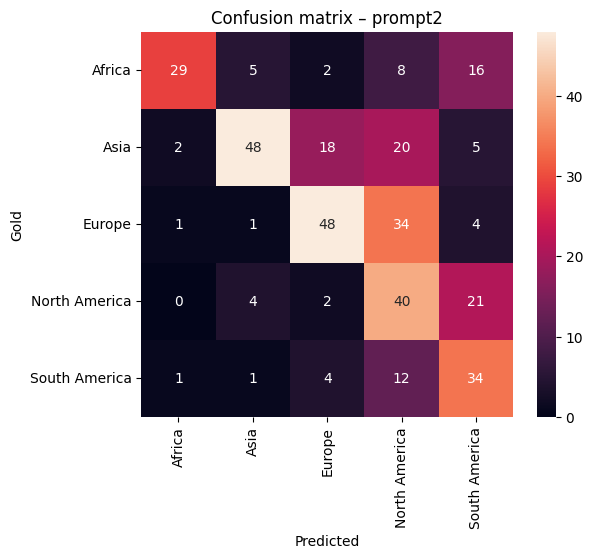

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

lvl = "prompt2"
mask = df_eval["prompt_level"] == lvl
y_true = df_eval.loc[mask, "dataset_continent"]
y_pred = df_eval.loc[mask, "pred_continent"]

cm = confusion_matrix(y_true, y_pred, labels=continents)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=continents, yticklabels=continents)
plt.xlabel("Predicted")
plt.ylabel("Gold")
plt.title(f"Confusion matrix – {lvl}")
plt.show()


In [ ]:

# Example Run

# 1) Clean raw JSONs (once)
clean_all_jsons()

# 2) Build unified dataframes
df_all, df_analysis = build_unified_dataframe()

# 3) (Optional) Save them
save_outputs(df_all, df_analysis)

# 4) Compute metrics
compute_metrics(df_analysis)

# 5) Plot confusion matrix for prompt2 and optionally save
plot_confusion(df_analysis, prompt_level="prompt2",
#                save_path=BASE_DIR / "figures" / "confusion_prompt2.png")